In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')
df = df[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


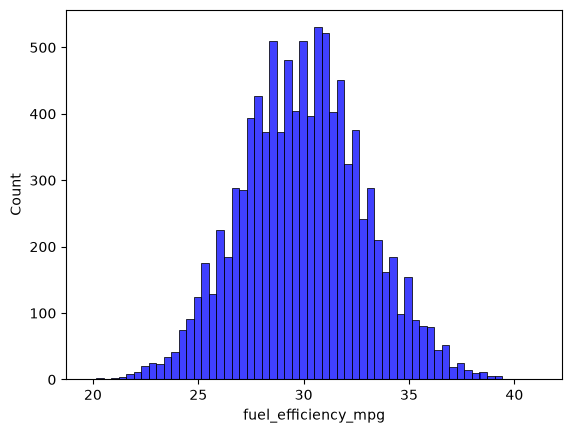

In [3]:
# EDA: Look at the `fuel_efficiency_mpg` variable. Does it have a long tail?
sns.histplot(df.fuel_efficiency_mpg, color='blue');

In [4]:
# Question 1: There's one column with missing values. What is it?
df.columns[len(df) - df.count() != 0]

Index(['horsepower'], dtype='str')

In [5]:
# Question 2: What's the median (50% percentile) for variable 'horsepower'?
df['horsepower'].median()

np.float64(254.0)

In [6]:
"""
Prepare and split the dataset: 
Shuffle the filtered dataset and create the split exactly as in the lecture (
    https://www.youtube.com/watch?v=ck0IfiPaQi0&list=PL3MmuxUbc_hIhxl5Ji8t4O6lPAOpHaCLR&index=16
). For Q5, repeat the same block with each listed seed. For Q6, use seed 9.
"""
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [7]:
"""
Question 3:
    We need to deal with missing values for the column from Q1.
    We have two options: fill it with 0 or with the mean of this variable.
    Try both options. For each, train a linear regression model without regularization using the code from the lessons.
    For computing the mean, use the training only!
    Use the validation dataset to evaluate the models and compare the RMSE of each option.
    Round the RMSE scores to 3 decimal digits using round(score, 3). This keeps the imputation difference visible in this release.
    Which option gives better RMSE?
"""
def linear_regression(X, w0, w):
    return w0 + X.dot(w)

    
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]
    

def prepare_X(df, fillna_val = 0):
    return df.copy().fillna(fillna_val)

    
def rmse(y_pred, y):
    sq_err = (y_pred - y) ** 2
    mean_sq_err = sq_err.mean()
    return np.sqrt(mean_sq_err)


X_train_zeroes = prepare_X(df_train)
w0_zeroes, w_zeroes = train_linear_regression(X_train_zeroes, y_train)
X_val_zeroes = prepare_X(df_val)
y_val_pred_zeroes = linear_regression(
    X_val_zeroes, 
    w0_zeroes, 
    w_zeroes
)
rmse_zeroes = round(rmse(y_val_pred_zeroes, y_val), 3)

X_train_mean = prepare_X(df_train, df_train.horsepower.mean())
w0_mean, w_mean = train_linear_regression(X_train_mean, y_train)
X_val_mean = prepare_X(df_val, df_val.horsepower.mean())
y_val_pred_mean = linear_regression(
    X_val_mean,
    w0_mean,
    w_mean
)
rmse_mean = round(rmse(y_val_pred_mean, y_val), 3)

rmse_zeroes, rmse_mean, rmse_mean < rmse_zeroes

(np.float64(2.205), np.float64(2.202), np.True_)

<Axes: ylabel='Count'>

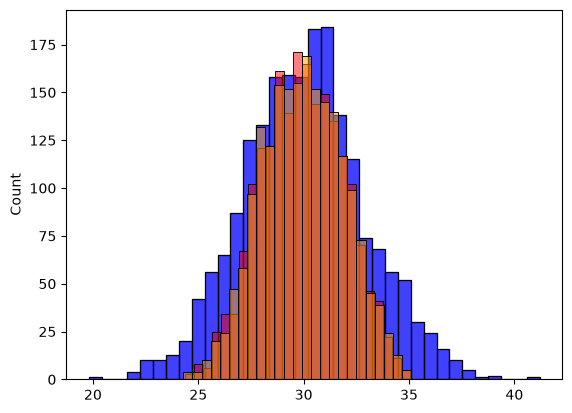

In [8]:
sns.histplot(y_val, color='blue')
sns.histplot(y_val_pred_zeroes, color='red', alpha=0.5);
sns.histplot(y_val_pred_mean, color='orange', alpha=0.5)

In [9]:
"""
Question 4:
    Now let's train a regularized linear regression.
    For this question, fill the NAs with 0.
    Try different values of r from this list: [0, 0.01, 0.1, 1, 5, 10, 100].
    Use RMSE to evaluate the model on the validation dataset.
    Round the RMSE scores to 4 decimal digits. This keeps the small but real regularization differences visible instead of turning several choices into a tie.
    Which r gives the best RMSE?
If multiple options give the same best RMSE, select the smallest r.
"""
def train_linear_regression_reg(X, y, r):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

    
X_train = prepare_X(df_train)
X_val = prepare_X(df_val)

r_vals = [0, 0.01, 0.1, 1, 5, 10, 100]
r_rmses = {}

for r in r_vals:
    w0_r, w_r = train_linear_regression_reg(X_train, y_train, r)
    y_val_pred_r = linear_regression(X_val, w0_r, w_r)
    r_rmses[r] = round(rmse(y_val_pred_r, y_val), 4)

min(r_rmses, key=lambda k: r_rmses[k])

0

In [10]:
"""
Question 5:
    We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
    Try different seed values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9].
    For each seed, do the train/validation/test split with 60%/20%/20% distribution.
    Fill the missing values with 0 and train a model without regularization.
    For each seed, evaluate the model on the validation dataset and collect the RMSE scores.
    What's the standard deviation of all the scores? To compute the standard deviation, use np.std.
    Round the result to 3 decimal digits (round(std, 3))
What's the value of std?
Note: Standard deviation shows how different the values are. If it's low, then all values are approximately the same. If it's high, the values are different. If standard deviation of scores is low, then our model is stable.
"""
seed_vals = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
seed_rmse = {}

for seed in seed_vals:
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)
    
    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]
    
    df_train = df_train.reset_index(drop=True)
    df_val = df_val.reset_index(drop=True)
    df_test = df_test.reset_index(drop=True)
    
    y_train = df_train.fuel_efficiency_mpg.values
    y_val = df_val.fuel_efficiency_mpg.values
    y_test = df_test.fuel_efficiency_mpg.values
    
    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    X_train = prepare_X(df_train)
    w0, w = train_linear_regression(X_train, y_train)
    X_val = prepare_X(df_val)
    y_val_pred = linear_regression(X_val, w0, w)
    seed_rmse[seed] = rmse(y_val_pred, y_val)
    
round(np.std(list(seed_rmse.values())), 3)

np.float64(0.029)

In [12]:
"""
Question 6:
    Split the dataset like previously, use seed 9.
    Combine train and validation datasets.
    Fill the missing values with 0 and train a model with r=0.001.
    What's the RMSE on the test dataset?
"""
np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]
# df_val_test = pd.concat([df_val, df_test])

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
# df_val_test = df_val_test.reset_index(drop=True)

y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values
# y_val_test = df_val_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']
# del df_val_test['fuel_efficiency_mpg']

X_train = prepare_X(df_train)
X_test = prepare_X(df_test)
w0, w = train_linear_regression_reg(X_train, y_train, 0.001)
y_test_pred = linear_regression(X_test, w0, w)
rmse_test = rmse(y_test_pred, y_test)

rmse_test
# X_train = prepare_X(df_train)
# X_val_test = prepare_X(df_val_test)
# w0, w = train_linear_regression_reg(X_train, y_train, 0.001)
# y_val_test_pred = linear_regression(X_val_test, w0, w)
# rmse_val_test = rmse(y_val_test_pred, y_val_test)

# rmse_val_test

np.float64(2.236415641600876)